#Members

        0002 Aiza Nabi


        0042 Ijaz Ul Haq


        0050 Zunair Qadeer

#Instructor

    Dr. Zia Ul  Rahman
## Project Title
# 🫀 Heart Disease (CHD) Prediction
 Framingham Heart Study — 10-Year Risk Prediction


---
We have build a **Logistic Regression** model to predict the **10-year risk** of Coronary Heart Disease (CHD) using real-world clinical data from the **Framingham Heart Study**.

### 📌 Project Flow:
1. **Load & Explore Data** — Understand the dataset
2. **EDA** — Visualize patterns and clinical insights
3. **Preprocessing** — Clean, engineer features, split & scale
4. **Model Training** — Logistic Regression with balanced class weights
5. **Threshold Tuning** — Youden's J statistic for optimal decision boundary
6. **Model Evaluation** — ROC-AUC, PR Curve, Confusion Matrix
7. **Save Model** — Export `.pkl` files for the Streamlit app

### 🎯 Target Variable: `TenYearCHD`
| Value | Meaning |
|---|---|
| 0 | No CHD in next 10 years (Healthy) |
| 1 | CHD diagnosed within next 10 years (At Risk) |
# ─────────────────────────────────────────────────────

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, recall_score, classification_report, 
    confusion_matrix, roc_curve, auc, precision_recall_curve
)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
%matplotlib inline


## 📂 Step 1: Load & Explore the Dataset
We begin by loading the **Framingham Heart Study** CSV file and taking a first look at its structure.

### 🔑 Key Features:
| Feature | Description |
|---|---|
| `age` | Patient age (years) |
| `male` | Sex (1 = Male, 0 = Female) |
| `cigsPerDay` | Cigarettes smoked per day |
| `totChol` | Total cholesterol (mg/dL) |
| `sysBP` | Systolic blood pressure |
| `diaBP` | Diastolic blood pressure |
| `BMI` | Body Mass Index |
| `glucose` | Blood glucose level (mg/dL) |
| `TenYearCHD` | 🎯 **Target** — 10-year CHD risk |

In [2]:
df = pd.read_csv('framingham.csv')

print(f'📊 Dataset Shape: {df.shape[0]} rows × {df.shape[1]} columns')
print(f'\n🎯 Target Variable Distribution:')
counts = df['TenYearCHD'].value_counts().sort_index()
for label, count in counts.items():
    pct = count / len(df) * 100
    emoji = '✅' if label == 0 else '⚠️'
    status = 'Healthy' if label == 0 else 'At Risk'
    print(f'    {emoji} {status} ({int(label)}): {count} patients ({pct:.1f}%)')

df.head()

📊 Dataset Shape: 4240 rows × 16 columns

🎯 Target Variable Distribution:
    ✅ Healthy (0): 3596 patients (84.8%)
    ⚠️ At Risk (1): 644 patients (15.2%)


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


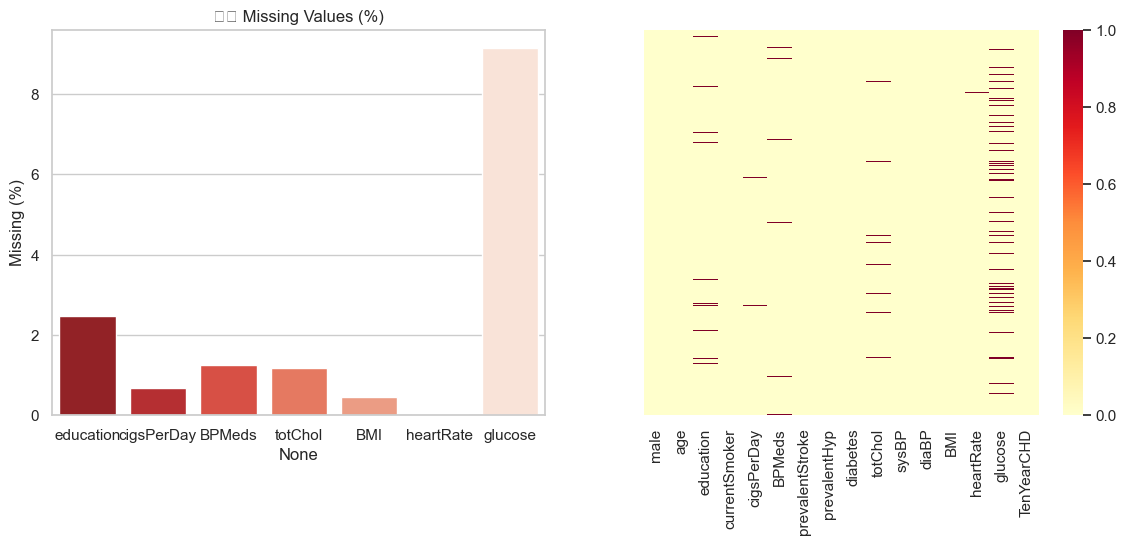

In [3]:
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Missing (%)': missing_pct}).query('`Missing Count` > 0')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=missing_df.index, y=missing_df['Missing (%)'], ax=axes[0], palette='Reds_r')
axes[0].set_title('⚠️ Missing Values (%)')
sns.heatmap(df.isnull(), yticklabels=False, cmap='YlOrRd', ax=axes[1])
plt.show()

In [4]:
# 1. Impute
imputer = SimpleImputer(strategy='median')
df_imputed = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

# 2. Rename & Feature Engineering
df_imputed.rename(columns={'male': 'Is_Male'}, inplace=True)
df_imputed['PulsePressure'] = df_imputed['sysBP'] - df_imputed['diaBP']

# 3. Feature Selection (Crucial: 9 Features)
FEATURES = ['age', 'Is_Male', 'cigsPerDay', 'totChol', 'sysBP', 'glucose', 'diaBP', 'BMI', 'PulsePressure']
X = df_imputed[FEATURES]
y = df_imputed['TenYearCHD'].astype(int)

# 4. Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 5. Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f'✅ Preprocessing Complete. Features: {len(FEATURES)}')

✅ Preprocessing Complete. Features: 9


In [5]:
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_proba = model.predict_proba(X_test_scaled)[:, 1]
print('✅ Model trained with balanced weights.')

✅ Model trained with balanced weights.


🚀 Optimal Threshold (Youden's J): 0.355


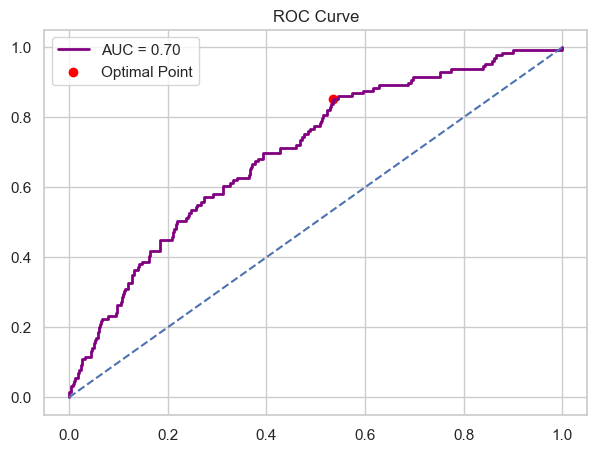

In [6]:
# Calculate ROC and find Youden's J
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
j_scores = tpr - fpr
best_idx = np.argmax(j_scores)
opt_threshold = thresholds[best_idx]

print(f"🚀 Optimal Threshold (Youden's J): {opt_threshold:.3f}")

# Plot ROC
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='purple', lw=2, label=f'AUC = {auc(fpr, tpr):.2f}')
plt.scatter(fpr[best_idx], tpr[best_idx], color='red', label='Optimal Point')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.legend()
plt.title('ROC Curve')
plt.show()

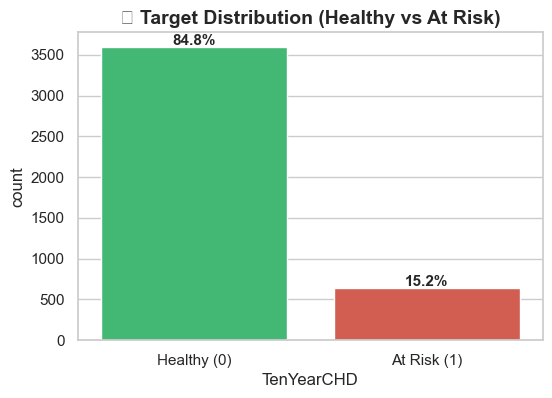

In [7]:
# ──────────────────────────────────────────────────────────
# 📊 EDA: Target Class Distribution
# ──────────────────────────────────────────────────────────
plt.figure(figsize=(6, 4))
colors = ['#2ecc71', '#e74c3c']
ax = sns.countplot(x=y, palette=colors)

# Adding percentages on top of bars
total = len(y)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    ax.annotate(percentage, (p.get_x() + p.get_width() / 2., p.get_height() + 20),
                ha='center', fontsize=11, fontweight='bold')

plt.title('🎯 Target Distribution (Healthy vs At Risk)', fontsize=14, fontweight='bold')
plt.xticks(ticks=[0, 1], labels=['Healthy (0)', 'At Risk (1)'])
plt.show()

In [10]:
y_pred_default = (y_proba >= 0.5).astype(int)
y_pred_opt = (y_proba >= opt_threshold).astype(int)

print(f'🏆 FINAL PERFORMANCE COMPARISON')
print(f'{"─"*40}')
print(f'Accuracy (Opt): {accuracy_score(y_test, y_pred_opt)*100:.1f}%')
print(f'Recall   (Opt): {recall_score(y_test, y_pred_opt)*100:.1f}%')
print(f'{"─"*40}')

🏆 FINAL PERFORMANCE COMPARISON
────────────────────────────────────────
Accuracy (Opt): 52.4%
Recall   (Opt): 85.3%
────────────────────────────────────────


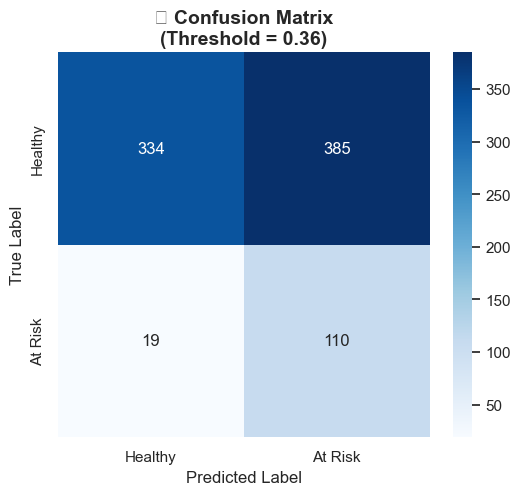


📌 Interpretation:
➜ True Negatives (Healthy correctly identified): 334
➜ True Positives (At Risk correctly identified): 110
➜ False Negatives (Missed CHD cases): 19 ⚠️


In [11]:
# ──────────────────────────────────────────────────────────
# 📋 Confusion Matrix (Optimized Threshold)
# ──────────────────────────────────────────────────────────
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_opt)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Healthy', 'At Risk'], 
            yticklabels=['Healthy', 'At Risk'])

plt.title(f'📋 Confusion Matrix\n(Threshold = {opt_threshold:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

print("\n📌 Interpretation:")
print(f"➜ True Negatives (Healthy correctly identified): {cm[0][0]}")
print(f"➜ True Positives (At Risk correctly identified): {cm[1][1]}")
print(f"➜ False Negatives (Missed CHD cases): {cm[1][0]} ⚠️")

In [12]:
# 1. Save objects
joblib.dump(model, 'heart_disease_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

# 2. Save Metadata JSON (Matches new app.py logic)
metadata = {
    "optimal_threshold": float(opt_threshold),
    "features": FEATURES
}

with open('model_config.json', 'w') as f:
    json.dump(metadata, f, indent=4)

print("✅ Files generated: heart_disease_model.pkl, scaler.pkl, model_config.json")

✅ Files generated: heart_disease_model.pkl, scaler.pkl, model_config.json
